In [1]:
import sys
sys.path.append('../')

import numpy as np

In [2]:
from fmodeling.forward_proc_1D import forward_with_trace_calcing

In [5]:
from inversion.Strategies.SeismDiffInversion1D import inverse
from inversion.optimizators.optimizations import LBFGSBOptimization, DifferentialEvolution, TrustKrylov, TrustConstr, \
    ConjugateGradient, AxOptimizer
# from Tests.test_ForwardProcessing1D import get_model_2layered, get_model_3layered
# from Data.geol_models import get_model_3layered_fluid_rp_dicts
from objects.data.WavePlaceholder import OWT, WaveDataPlaceholder
from objects.models.Models import SeismicModel1D
from objects.attributes.rock_physics.RockPhysicsAttribute import RockPhysicsAttribute
from objects.attributes.seismic.SeismicAttribute import SeismicAttribute
from objects.models.Layer1D import Layer1D, LayerOPT
import time

from matplotlib import pyplot as plt
from inversion.Strategies.SeismDiffInversion1D import func_to_optimize
from visualization.Seismic import visualize_model1D, visualize_rays_model_1D, visualize_time_curves


/Users/apenkin/opt/anaconda3/envs/rpsi/lib/python3.7/site-packages/llvmlite/llvmpy/__init__.py:4: UserWarning: The module `llvmlite.llvmpy` is deprecated and will be removed in the future.
  "The module `llvmlite.llvmpy` is deprecated and will be removed in the "
/Users/apenkin/opt/anaconda3/envs/rpsi/lib/python3.7/site-packages/llvmlite/llvmpy/core.py:9: UserWarning: The module `llvmlite.llvmpy.core` is deprecated and will be removed in the future. Equivalent functionality is provided by `llvmlite.ir`.
  "The module `llvmlite.llvmpy.core` is deprecated and will be removed in "
/Users/apenkin/opt/anaconda3/envs/rpsi/lib/python3.7/site-packages/llvmlite/llvmpy/passes.py:18: UserWarning: The module `llvmlite.llvmpy.passes` is deprecated and will be removed in the future. If you are using this code, it should be inlined into your own project.
  "The module `llvmlite.llvmpy.passes` is deprecated and will be removed in "


In [6]:
import json


In [7]:
from visualization.Seismic import visualize_seismogram
from scipy.optimize import approx_fprime


In [8]:
def plot_1D_err(forward_params, nvals, min_max=None, dot=False, vline_x=None, ax=None, 
                err_func=None, err_func_params=None):
    
    if min_max is None:
        min_val = forward_params['model'].get_optimization_option("min", vectorize=True)
        max_val = forward_params['model'].get_optimization_option("max", vectorize=True)
        
    else:
        min_val = np.array([min_max[0]])
        max_val = np.array([min_max[1]])
    
    dval = (max_val - min_val) / nvals

    val_x = [min_val + dval*i for i in range(nvals+1)]
    errs = []
    
    if err_func is None:
        err_func = func_to_optimize
        err_func_params = [None, placeholders, forward_params, None, False]
    
    for val in val_x:
        err_func_params[0] = val
        errs.append(err_func(*err_func_params))
       
    show_flag = False
    if ax is None:
        fig, ax = plt.subplots()
        show_flag = True
        
    ax.plot(val_x, errs)
    if dot:
        ax.plot(val_x, errs, 'o')
        
    if vline_x is not None:
        ax.vlines(vline_x, ymin=min(errs), ymax=max(errs), colors='r')
        
    if show_flag:
        plt.show()

def optimization_func_2D(forward_params, x, y, err_func, err_func_params):
    indexes_1 = np.arange(x.shape[0])
    indexes_2 = np.arange(x.shape[1])
    
    Z = np.zeros((x.shape[0], x.shape[1]))
    
    for ind1 in indexes_1:
        for ind2 in indexes_2:
            err_func_params[0] = [x[ind1, ind2], y[ind1, ind2]]
            Z[ind1, ind2] = err_func(*err_func_params)
        
    return Z

def plot_2D_err(forward_params, nvals, ncontous=10, points=None, fig=None, ax=None, err_func=None, 
               err_func_params=None):
    min_val = forward_params['model'].get_optimization_option("min", vectorize=True)
    max_val = forward_params['model'].get_optimization_option("max", vectorize=True)
    
    if err_func is None:
        err_func = func_to_optimize
        err_func_params = [None, placeholders, forward_params, None, False]
    
    dval = (max_val - min_val) / nvals

    val_1_x = [min_val[0] + dval[0]*i for i in range(nvals[0]+1)]
    val_2_x = [min_val[1] + dval[1]*i for i in range(nvals[1]+1)]

    X, Y = np.meshgrid(val_1_x, val_2_x)

    Z = optimization_func_2D(forward_params, X, Y, err_func, err_func_params)
    
    if ax is None and fig is None:
        fig, ax = plt.subplots()
    
    im = ax.contourf(X, Y, Z, ncontous, cmap='seismic')
    fig.colorbar(im, ax=ax)
    
    if points is not None:
        ax.plot(points[0], points[1], marker='o', color='green', markersize=5)

# Four-layer model with gas-saturated sediments

In [9]:
h = [
    67.5,
    22.5,
    20
]

In [ ]:
layer_1_seism = {
    'vp': 1500,
    'vs': 700,
    'rho': 1000
}

def get_layer2_rp():
    return {
    "name": "unconsolidated",
    "components": {
                    "Ksi": {
                      "value": 38,
                      "optimize": True,
                      "min": 20,
                      "max": 60
                    },
					"Gsi": {
                      "value": 44,
                      "optimize": True,
                      "min": 20,
                      "max": 50
                    },
					"rhosi": {
                      "value": 2.2,
                      "optimize": True,
                      "min": 2,
                      "max": 2.5
                    },
                    "Ksh": {
                      "value": 21.5,
                      "optimize": True,
                      "min": 10,
                      "max": 50
                    },
					"Gsh": {
                      "value": 7,
                      "optimize": True,
                      "min": 1,
                      "max": 20
                    },
					"rhosh": {
                      "value": 2.43,
                      "optimize": True,
                      "min": 2,
                      "max": 2.5
                    },
                    "Kincl": {
                      "value": 36.9,
                      "optimize": False,
                      "min": 35,
                      "max": 40
                    },
                    "Gincl": {
                      "value": 31,
                      "optimize": False,
                      "min": 30,
                      "max": 35
                    },
                    "rhoincl": {
                      "value": 2.2,
                      "optimize": False,
                      "min": 2,
                      "max": 2.5
                    },
                    "Kfl": {
                      "value": 2.29,
                      "optimize": False,
                      "min": 0.5,
                      "max": 5
                    },
                    "rhofl": {
                      "value": 1,
                      "optimize": False,
                      "min": 0.5,
                      "max": 1.5
                    },
#                     "Vsi": {
#                       "value": 0.01,
#                       "optimize": False,
#                       "min": 0.5,
#                       "max": 0.99
#                     },
                    "Vsh": {
                      "value": 0.7,
                      "optimize": True,
                      "min": 0.5,
                      "max": 0.99
                    },
                    "Vincl": {
                      "value": 0,
                      "optimize": False,
                      "min": 0.5,
                      "max": 0.99
                    },
                    "phi": {
                      "value": 0.74,
                      "optimize": True,
                      "min": 0.5,
                      "max": 0.99
                    }
                  }
}

layer_2_rp = get_layer2_rp()

layer_3_seism = {
    'vp': 2000,
    'vs': 1000,
    'rho': 2070
}

layer_4_seism = {
    'vp': 6600,
    'vs': 3600,
    'rho': 2600,
}

In [11]:
optimization_list = [
#     "Ksi",
#     "Gsi",
#     "rhosi",
    "Ksh",
    "Gsh",
    "rhosh",
#     "Kfl",
#     "rhofl",
    "Vsh",
#     "Vincl",
    "phi"
]

decrease_boundaries = True

for key in layer_2_rp['components'].keys():
    if key in optimization_list:
        layer_2_rp['components'][key]["optimize"] = True
        
        if decrease_boundaries:
            layer_2_rp['components'][key]["min"] = layer_2_rp['components'][key]["value"] * 0.7
            layer_2_rp['components'][key]["max"] = layer_2_rp['components'][key]["value"] * 1.3
        
    else:
        layer_2_rp['components'][key]["optimize"] = False

In [12]:
layer_1 = Layer1D(h[0],
                  rp_attribute=None,
                  seism_attribute=SeismicAttribute(**layer_1_seism),
                  opt=LayerOPT.NO)
layer_2 = Layer1D(h[1],
                  rp_attribute=RockPhysicsAttribute(layer_2_rp['components'], layer_2_rp['name']),
                  seism_attribute=None,
                  opt=LayerOPT.RP)
layer_3 = Layer1D(h[2],
                  rp_attribute=None,
                  seism_attribute=SeismicAttribute(**layer_3_seism),
                  opt=LayerOPT.NO)
layer_4 = Layer1D(-1,
                  rp_attribute=None,
                  seism_attribute=SeismicAttribute(**layer_4_seism),
                  opt=LayerOPT.NO)

In [13]:
model = SeismicModel1D([layer_1, layer_2, layer_3, layer_4])

In [14]:
# Multichannel array of seismic receivers

In [15]:
dx = 2
nx = 100
x_rec = [i * dx for i in range(1, nx+1)]
wave_types = [OWT.PdPu_water]
dt = 1e-04
tracelen = 2000

# Forward modeling

In [16]:
observe, test_seismic = \
    forward_with_trace_calcing(model, x_rec,
                               dt=dt, trace_len=tracelen, wavetypes=wave_types, display_stat=True,
        visualize_res=False, visualize_seismograms=False)

Calculating rockphysics model...
Rockphysics model calculated!
Calculating PdPu_water-rays...


../fmodeling/seismic/dynamic/bounds.py:61: ComplexWarning: Casting complex values to real discards the imaginary part
  angles[idx])


In [17]:
true_vals = model.get_optimization_option('val')

In [18]:
true_vals

OrderedDict([(1,
              {'Ksh': 21.5,
               'Gsh': 7,
               'rhosh': 2.43,
               'Vsh': 0.7,
               'phi': 0.74})])

In [19]:
model.layers[0].seism_attribute.vals_dict

{'vp': 1500, 'vs': 700, 'rho': 1000}

In [20]:
model.layers[1].seism_attribute.vals_dict

{'vp': 1534.1089459244965, 'vs': 200.08822703140874, 'rho': 1353.8600000000001}

In [21]:
# fig, axes = plt.subplots(figsize=(15, 9))

# max_depth=300
# dz = 20

# visualize_model1D(axes, model, observe, max_depth, dz, 'vp', only_boundaries=True)
# visualize_rays_model_1D(axes, test_seismic[OWT.PdPu_water]["rays"])
# axes.invert_yaxis()

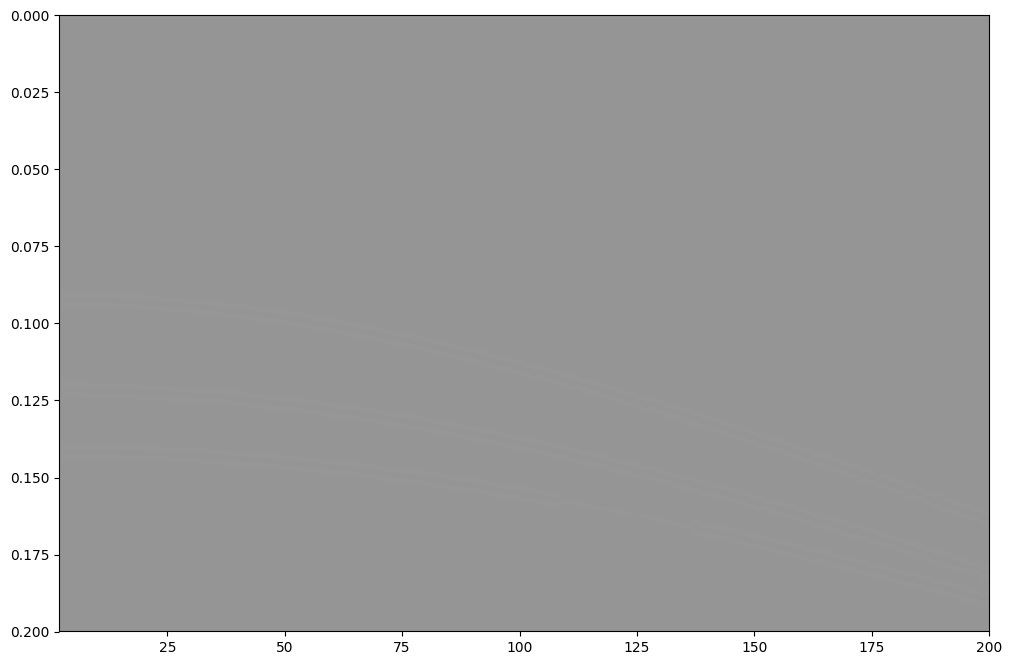

In [22]:
fig, ax = plt.subplots(figsize=(12,8))

visualize_seismogram(fig, ax, test_seismic[OWT.PdPu_water]['seismogram'], wiggles=False)
plt.show()

# Inversion

In [23]:
forward_params = {
    "model": model,
    "x_rec": x_rec,
    "dt": dt,
    "trace_len": tracelen,
    "wavetypes": wave_types,
    "display_stat": False,
    "visualize_res": False
}

## Create start indexes

In [24]:
def formula(v, h, x):
    return np.sqrt(x**2 + 4*h*h) / v

In [25]:
start_times = formula(1500, 60, np.array(x_rec))
start_indexes = (start_times / dt).astype(int)

In [26]:
wave_types

[<OWT.PdPu_water: 6>]

In [27]:
placeholders = {}
for wt in wave_types:
    placeholders[wt] = WaveDataPlaceholder(
        wt,
        test_seismic[wt]["rays"],
        test_seismic[wt]["seismogram"],
        start_indexes=start_indexes
    )

In [28]:
# json.dumps(placeholders[OWT.PdPu_water].rays[1][0])

## Create optimizers

In [29]:
optimizers_de = [
    DifferentialEvolution(
          popsize= 5,
          maxiter= 50000,
          init= "latinhypercube",
          strategy= "best1bin",
          disp= True,
          polish= True,
          tol= 0.00001,
          mutation= 1.5,
          recombination= 0.6,
          workers= 8
    )
]

In [30]:
optimizers_lbfgs = [
    LBFGSBOptimization(
        maxiter=15000,
        maxfun=15000,
        factr=100,
        maxls=50,
        pgtol=1e-7,
        epsilon=1e-7,
        iprint=1,
        disp=1
    )
]

In [31]:
optimizers_cg = [
    ConjugateGradient(
    )
]

In [32]:
optimizers_ax = [
    AxOptimizer(num_evals=30, log_scale=False)
]

In [33]:
min_vals = forward_params['model'].get_optimization_option('min', vectorize=True)
max_vals = forward_params['model'].get_optimization_option('max', vectorize=True)
start_vals = np.random.uniform(min_vals, max_vals)

print(min_vals, max_vals)
print(start_vals)

[15.05   4.9    1.701  0.49   0.518] [27.95   9.1    3.159  0.91   0.962]
[26.16662269  8.23275182  3.04173529  0.50765942  0.84219087]


In [34]:
start_vals = forward_params['model'].get_optimization_option('val', vectorize=True)*0.9
start_vals

array([19.35 ,  6.3  ,  2.187,  0.63 ,  0.666])

In [35]:
start_vals = [0.85, 0.7]

In [ ]:
# forward_params['model'].set_optimization_option(start_vals)

# func_to_optimize(forward_params['model'].get_optimization_option('val', vectorize=True), placeholders, forward_params, helper=None, show_tol=False)

ParamOutOfBoundException: 

## Check sensitivity

In [37]:
def func_(xk):
    return func_to_optimize(xk, placeholders, forward_params, helper=None, show_tol=False)

def func_min_max(xk):
    xk = min_vals + xk * (max_vals - min_vals)
    
    return func_to_optimize(xk, placeholders, forward_params, helper=None, show_tol=False)

nrepeats = 5

grads = []

for i in range(nrepeats):
    start_vals = np.random.uniform(min_vals, max_vals)
    start_vals_minmax = (start_vals - min_vals) / (max_vals - min_vals)
    
#     grads.append(approx_fprime(start_vals, func_, epsilon=[1e-6]*len(start_vals)))
    grads.append(approx_fprime(start_vals_minmax, func_min_max, epsilon=[1e-6]*len(start_vals)))
    
grads

../inversion/Utils/Calcs.py:52: RuntimeWarning: divide by zero encountered in true_divide
  arr = ((obs - mod) / obs) ** 2


[array([-0.06122772, -0.01278126,  0.08442906,  0.02236795,  0.86880222]),
 array([ 0.00520099,  0.03047957, -0.32580684, -0.06989887, -0.24882352]),
 array([-0.06479179, -0.01166112,  0.1046204 ,  0.02763737,  0.71410623]),
 array([-0.15722448, -0.04539012,  0.41747532,  0.19887825,  1.25639468]),
 array([-0.02259983, -0.00781805, -0.0022545 ,  0.01223216,  0.43162538])]

In [38]:
model.get_optimization_option('val')

OrderedDict([(1,
              {'Ksh': 26.301287524136377,
               'Gsh': 5.860647673029894,
               'rhosh': 2.4286896244841794,
               'Vsh': 0.7996135450574442,
               'phi': 0.5897127120184237})])

# Run inversion process

In [ ]:
# scale="minmax"
scale=None
# scale="lg"

start_time = time.time()
inversed_vals, stats = inverse(optimizers_de, error=None, placeholders=placeholders, forward_params=forward_params, scale=scale)
print(f"time: {time.time() - start_time}")

In [105]:
forward_params['model'].set_optimization_option(inversed_vals)
forward_params['model'].scale=None
inversed_vals = forward_params['model'].get_optimization_option('val', vectorize=True)

In [106]:
inversed_vals

array([0.70000005, 0.73999999])

In [107]:
result = {key: {
    "real": val,
    "inversed": inv
} for key, val, inv in zip(true_vals[1].keys(), true_vals[1].values(), inversed_vals)}
result

{'Vsh': {'real': 0.7, 'inversed': 0.7000000520567508},
 'phi': {'real': 0.74, 'inversed': 0.7399999924754297}}

In [68]:
time_1 = time.time()
func_to_optimize(inversed_vals, placeholders, forward_params, helper=None, show_tol=False)
print(time.time() - time_1)

0.1377875804901123


Calculating rockphysics model...
Rockphysics model calculated!
Calculating PdPu_water-rays...


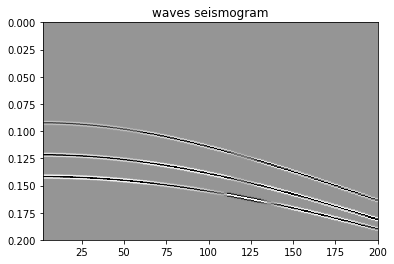

In [65]:
res_observe, res_seismic = forward_with_trace_calcing(forward_params['model'], forward_params['x_rec'], 
                           dt=forward_params['dt'], 
                           trace_len=forward_params['trace_len'], 
                           wavetypes=forward_params['wavetypes'],
            display_stat=True, visualize_res=False,
                               visualize_seismograms=True
            )

In [ ]:
diff = test_seismic[OWT.PdPu_water]['seismogram'] - res_seismic[OWT.PdPu_water]['seismogram']
fig, ax = plt.subplots(figsize=(12,8))

visualize_seismogram(fig, ax, diff, wiggles=False)
plt.show()